In [1]:
# Orange Fruit Quality Classification with a CNN
# Dataset: https://doi.org/10.17632/zk4hzhtcdd.2
import random
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001
DROPOUT = 0.5
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda


In [2]:
# Load images and split each class into 70% train, 15% validation, 15% test.
data_dir = next(p for p in Path('/kaggle/input').rglob('dataset')
                if (p / 'fresh_orange').is_dir())
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])
data = datasets.ImageFolder(data_dir, transform=transform)
train_ids, val_ids, test_ids = [], [], []
rng = random.Random(SEED)
for label in range(len(data.classes)):
    ids = [i for i, target in enumerate(data.targets) if target == label]
    rng.shuffle(ids)
    a = int(0.70 * len(ids))
    b = a + int(0.15 * len(ids))
    train_ids.extend(ids[:a])
    val_ids.extend(ids[a:b])
    test_ids.extend(ids[b:])

train_loader = DataLoader(Subset(data, train_ids), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(Subset(data, val_ids), batch_size=BATCH_SIZE, num_workers=2)
test_loader = DataLoader(Subset(data, test_ids), batch_size=BATCH_SIZE, num_workers=2)
print('Classes:', data.classes)
print('Train:', len(train_ids), '| Validation:', len(val_ids), '| Test:', len(test_ids))


Classes: ['blackspotted_orange', 'cankered_orange', 'fresh_orange', 'green_orange', 'rotten_orange']
Train: 10500 | Validation: 2250 | Test: 2250


In [3]:
# Three simple convolution blocks. Each MaxPool halves height and width.
model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2), # 64 -> 32
    nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2), # 32 -> 16
    nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2), # 16 -> 8
    nn.Flatten(),
    nn.Dropout(p=DROPOUT),
    nn.Linear(64 * (IMAGE_SIZE // 8) ** 2, 64),
    nn.ReLU(),
    nn.Linear(64, len(data.classes))
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0)
parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print('Learning rate:', LEARNING_RATE, '| Trainable parameters:', parameters)


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Dropout(p=0.5, inplace=False)
  (11): Linear(in_features=4096, out_features=64, bias=True)
  (12): ReLU()
  (13): Linear(in_features=64, out_features=5, bias=True)
)
Learning rate: 0.001 | Trainable parameters: 286117


In [4]:
# train() enables dropout; eval() disables dropout for validation and testing.
def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total

history = []
best_val_loss = float('inf')
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader)
    history.append([epoch, train_loss, val_loss, train_acc, val_acc])
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), '/kaggle/working/orange_cnn.pt')
    print(f'Epoch {epoch}/{EPOCHS} | Train loss {train_loss:.4f}, acc {train_acc:.2f}%'
          f' | Val loss {val_loss:.4f}, acc {val_acc:.2f}%', flush=True)


Epoch 1/10 | Train loss 0.6409, acc 74.76% | Val loss 0.3624, acc 87.11%
Epoch 2/10 | Train loss 0.3365, acc 87.83% | Val loss 0.3280, acc 88.22%
Epoch 3/10 | Train loss 0.2342, acc 91.69% | Val loss 0.1794, acc 93.78%
Epoch 4/10 | Train loss 0.1810, acc 93.74% | Val loss 0.1835, acc 93.51%
Epoch 5/10 | Train loss 0.1514, acc 94.63% | Val loss 0.1214, acc 95.29%
Epoch 6/10 | Train loss 0.1226, acc 95.59% | Val loss 0.1491, acc 94.71%
Epoch 7/10 | Train loss 0.0978, acc 96.39% | Val loss 0.0837, acc 96.98%
Epoch 8/10 | Train loss 0.1038, acc 96.19% | Val loss 0.0823, acc 96.36%
Epoch 9/10 | Train loss 0.0812, acc 96.88% | Val loss 0.1123, acc 95.87%
Epoch 10/10 | Train loss 0.0777, acc 97.09% | Val loss 0.0889, acc 96.36%


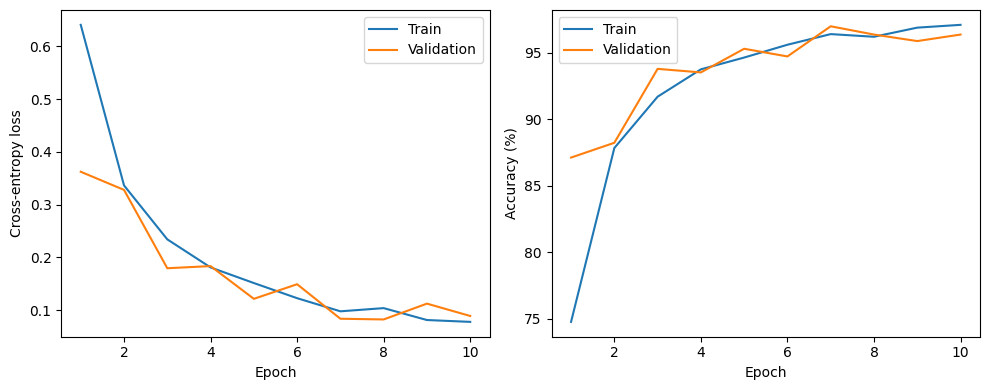

In [5]:
# Plot and save training results.
history = pd.DataFrame(history, columns=['epoch', 'train_loss', 'val_loss', 'train_acc', 'val_acc'])
history.to_csv('/kaggle/working/orange_training_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.epoch, history.train_loss, label='Train')
axes[0].plot(history.epoch, history.val_loss, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].plot(history.epoch, history.train_acc, label='Train')
axes[1].plot(history.epoch, history.val_acc, label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/orange_training_curves.png')
plt.show()


In [6]:
# Test the checkpoint selected using validation loss.
model.load_state_dict(torch.load('/kaggle/working/orange_cnn.pt', map_location=device))
test_loss, test_acc = run_epoch(test_loader)
_, clean_train_acc = run_epoch(train_loader)
_, selected_val_acc = run_epoch(val_loader)
summary = pd.DataFrame([{
    'Training images': len(train_ids),
    'Validation images': len(val_ids),
    'Testing images': len(test_ids),
    'Classes': len(data.classes),
    'Test accuracy (%)': test_acc,
    'Test loss': test_loss,
    'Best validation loss': best_val_loss,
    'Train-val gap (percentage points)': clean_train_acc - selected_val_acc,
    'Epochs trained': EPOCHS,
    'Selected epoch': best_epoch,
    'Learning rate': LEARNING_RATE,
    'Trainable parameters': parameters,
    'Regularization': 'Dropout only',
    'Dropout probability': DROPOUT
}])
print(summary.T.to_string(header=False))
summary.to_csv('/kaggle/working/orange_submission_summary.csv', index=False)


Training images                           10500
Validation images                          2250
Testing images                             2250
Classes                                       5
Test accuracy (%)                          96.8
Test loss                              0.080354
Best validation loss                   0.082337
Train-val gap (percentage points)      1.149206
Epochs trained                               10
Selected epoch                                8
Learning rate                             0.001
Trainable parameters                     286117
Regularization                     Dropout only
Dropout probability                         0.5
